# Case study: the Maduro market (January 2026)
The Yes price path around the news, the buys of the wallet that official sources (CFTC, DOJ) describe, and its matched controls. The wallet is shown by address only; no identity work.

In [1]:
import pandas as pd, matplotlib.pyplot as plt, duckdb
DATA = '../data'; CASE = 'maduro-2026-01'
markets = pd.read_parquet(f'{DATA}/markets.parquet'); wallets = pd.read_parquet(f'{DATA}/wallets.parquet')
links = pd.read_parquet(f'{DATA}/claim_wallet_links.parquet')
w = wallets[(wallets.case_id == CASE) & wallets.label_strict]
print(w[['wallet','label_tier','wallet_grade','strict_basis']]); print(links[links.case_id == CASE])

                                       wallet  \
3  0x31a56e9e690c621ed21de08cb559e9524cdb8ed9   

                        label_tier wallet_grade     strict_basis  
3  L2_official_case_analyst_wallet           E2  wallet_grade_E2  
   claim_id                                      wallet         case_id  \
13   CL0001  0x31a56e9e690c621ed21de08cb559e9524cdb8ed9  maduro-2026-01   
14   CL0002  0x31a56e9e690c621ed21de08cb559e9524cdb8ed9  maduro-2026-01   
15   CL0003  0x31a56e9e690c621ed21de08cb559e9524cdb8ed9  maduro-2026-01   
16   CL0004  0x31a56e9e690c621ed21de08cb559e9524cdb8ed9  maduro-2026-01   
17   CL0121  0x31a56e9e690c621ed21de08cb559e9524cdb8ed9  maduro-2026-01   

                 link_type evidence_grade subject_type  
13  official_figures_match             E2      account  
14  official_figures_match             E2      account  
15         resolved_handle             E5       handle  
16        address_in_claim             E5      address  
17  official_figures_match     

In [2]:
W = w.wallet.iloc[0]
ep = pd.read_parquet(f'{DATA}/episodes.parquet', filters=[('case_id','==',CASE), ('t_news_version','==','precise')])
e = ep[(ep.wallet == W) & (ep.role == 'suspected')].sort_values('pre_buy_usdc', ascending=False).iloc[0]
cid = e.condition_id; m = markets.set_index(['case_id','condition_id']).loc[(CASE, cid)]
print(m.question, '| t_news', m.t_news_utc, '| precise', m.t_news_precise_utc, m.t_news_precise_precision)
ctl = pd.read_parquet(f'{DATA}/controls.parquet', filters=[('t_news_version','==','precise'), ('episode_id','==',e.episode_id)])
ctl[['wallet','control_type','relaxation','first_buy_price_usdc','size_usdc']].head(12)

Maduro out by January 31, 2026? | t_news 2026-01-03 00:00:00+00:00 | precise 2026-01-03 05:30:00+00:00 quarter_hour


,wallet,control_type,relaxation,first_buy_price_usdc,size_usdc
0,0xf797d4d1c038d1eb0593edae0e66bf8e4b2e0bf2,same_side,size_0.25_4x,0.06,2070.396385
1,0xfe0ad5ed4c912a46a4e41198e673bd371c384a63,same_side,size_0.25_4x,0.09,1554.187072
2,0xe02c5438dfb907d5ac4cbf3967b45d14e4ed5d08,other_side_large_buyer,base,0.91,7279.998988
3,0x33d2b3adab3cd8d92e81a3bdb46e3315c709952e,other_side_large_buyer,base,0.90,5940.000000
4,0x1f0a343513aa6060488fabe96960e6d1e177f7aa,other_side_large_buyer,base,0.90,2382.720100
5,0x280fafa15eac6ef01bde0bd80ad89d0cd6a76635,other_side_large_buyer,base,0.93,2352.900000
6,0xbf935ba3c9add3c744a7e7ecca070a7e34c96e4f,other_side_large_buyer,base,0.90,2074.877600
7,0x35b069f99d666bb70aa8d7a456a4658c9a6a7835,other_side_large_buyer,base,0.92,1904.400000
8,0xfeeebcf1bc01c2c3b676f876cbad907ddc1fa4a9,other_side_large_buyer,base,0.92,1830.000000
9,0x0523ff55bd7525d5fbda5c77f80f61662db4e38b,other_side_large_buyer,base,0.92,1816.860000


124 legs of the wallet in this market; buys before the precise cut: 39


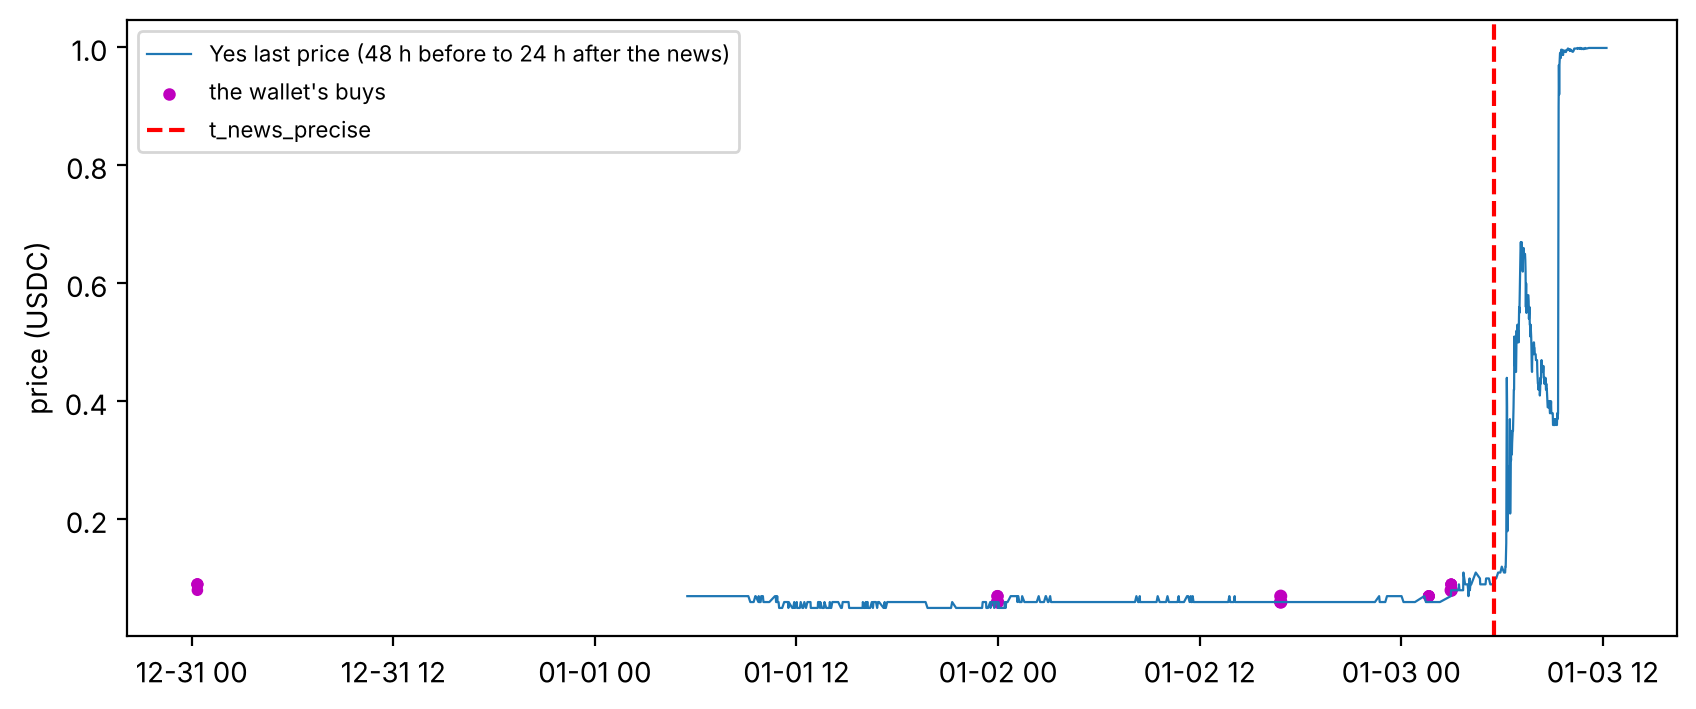

In [3]:
f = duckdb.sql(f"SELECT ts_utc, price_usdc, usdc, wallet_side FROM read_parquet('{DATA}/fills_part*_case_*.parquet') WHERE condition_id = '{cid}' AND wallet = '{W}' ORDER BY ts_unix").df()
mm = pd.read_parquet(f'{DATA}/market_minutes.parquet', filters=[('case_id','==',CASE), ('condition_id','==',cid), ('t_news_version','==','precise'), ('market_set','==','case')])
fig, ax = plt.subplots(figsize=(10,4)); ax.plot(mm.minute_utc, mm.last_price_usdc, lw=0.8, label='Yes last price (48 h before to 24 h after the news)')
b = f[f.wallet_side == 'BUY']; ax.scatter(b.ts_utc, b.price_usdc, s=10 + b.usdc / 200, color='m', label='the wallet\'s buys')
ax.axvline(pd.Timestamp(m.t_news_precise_utc), color='r', ls='--', label='t_news_precise'); ax.legend(fontsize=8); ax.set_ylabel('price (USDC)')
print(len(f), 'legs of the wallet in this market; buys before the precise cut:', (b.ts_utc < pd.Timestamp(m.t_news_precise_utc)).sum())

In [4]:
# the matched controls bought the same token, at a similar time, price and size; how did they do?
ep[ep.control_of == e.row_id].groupby('role').agg(n=('wallet','size'), won=('won_post','mean'), median_buy_usdc=('pre_buy_usdc','median'))

,n,won,median_buy_usdc
role,,,
